In [1]:
# Kaggle environment setup
import numpy as np
import pandas as pd
import os

# Do NOT recursively walk /kaggle/input. The RSNA knee dataset contains hundreds of
# thousands of DICOM files, so os.walk() here adds unnecessary startup time.
COMP = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

print("Kaggle environment ready")
print("data root:", COMP)

required_files = [
    "train.csv",
    "test.csv",
    "train_series.csv",
    "test_series.csv",
]

for name in required_files:
    path = os.path.join(COMP, name)
    print(name, "->", os.path.exists(path))

assert os.path.isdir(COMP), f"Competition data folder not found: {COMP}"
for name in required_files:
    assert os.path.isfile(os.path.join(COMP, name)), f"Missing required file: {name}"


Kaggle environment ready
data root: /kaggle/input/competitions/rsna-knee-abnormality-detection
train.csv -> True
test.csv -> True
train_series.csv -> True
test_series.csv -> True


**Important submission fix.** The public `test.csv`, `test_series.csv`, and test DICOMs contain only a few example studies. During code-competition scoring, Kaggle replaces them with the hidden test set. The notebook therefore must not assume that `sample_submission.csv` contains the hidden test IDs. We use `test.csv` as the source of truth for the submitted IDs and use `sample_submission.csv` only as an optional schema check.


# RSNA Knee - v4 (5 fold models averaged, one switch per experiment)

The goal of this notebook is to prove the complete Kaggle code-submission chain works on both the public example data and Kaggle's hidden replacement test data: read the data, build the baseline model, read DICOM images safely, predict the test studies, and write a valid `submission.csv`.

The competition requires notebook submissions, a maximum 9-hour CPU/GPU notebook runtime, internet disabled, and an output file named `submission.csv`. Freely and publicly available external data, including pretrained models, is allowed.

## 1. Settings

v4 trains **5 models**, each on 4/5 of the studies, and averages them. Each model is checked on the
1/5 it did not see, so every study gets one honest prediction (the "OOF" score).

The lines under `v4 experiments` are switches. **Change one switch per run** and write the
`RESULT` line printed at the end of training into the table in section 12. Keep a change only if
it helps.

With the `knee-train-cache` dataset attached, a run takes about 1.5 hours. Without it, the DICOMs
are read again first (about 4 hours).

In [2]:
TRAIN_STUDIES = 5000     # more than exist, so every usable study is used
SLICES_PER_PLANE = 12    # must divide by 3
IMG_SIZE = 224           # E5: 288 (needs a new cache)
CROP_MM = 140.0          # E5: 130.0

EPOCHS = 5               # was 8: in v3 the scores stopped rising after epoch 3-4
BATCH_SIZE = 8
LEARNING_RATE = 3e-4
SEED = 42

# v4 experiments. Change ONE line per run.
N_FOLDS = 5              # E1: 5 models averaged. 1 = a single model like v3
POOLING = "meanmax"      # E2: "attention" (knows where each slice is, one attention per finding)
LOSS = "pooled"          # E3: "per_finding" (rarely-clear findings like Fracture count more)
AUGMENT = False          # E4: True = small rotation, zoom and shift
BACKBONE = "resnet34"    # E6: "resnet50" (same weights dataset)

## 2. Imports and where the data is

Kaggle puts competition data in one of two folders depending on how it was attached, so we
check both.

In [3]:
import os
import glob
import time
import random
import re
import psutil

import cv2
import numpy as np
import pandas as pd
import pydicom
import torch
import torch.nn as nn
import timm
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score

try:
    from pydicom.pixels import apply_voi_lut
except ImportError:
    from pydicom.pixel_data_handlers.util import apply_voi_lut


CANDIDATES = [
    "/kaggle/input/competitions/rsna-knee-abnormality-detection",
    "/kaggle/input/rsna-knee-abnormality-detection",
]
COMP = next(path for path in CANDIDATES if os.path.exists(path))

LABELS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

PLANES = ["Sagittal", "Coronal", "Axial"]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("data root :", COMP)
print("device    :", DEVICE)
print("torch     :", torch.__version__)
print("cuda      :", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("cpu cores :", os.cpu_count())
print(f"RAM       : {psutil.virtual_memory().total / 1e9:.1f} GB total, "
      f"{psutil.virtual_memory().available / 1e9:.1f} GB free")

assert DEVICE == "cuda", "GPU accelerator is required for this notebook."
assert torch.cuda.is_available(), "CUDA is not available. Set Kaggle Accelerator to GPU T4 x2."

# ImageNet ResNet34 weights. Attach the public dataset
# "PyTorch ResNet-(18, 34, 50, 101, 152) Pretrained" with Add Input -> Datasets.
# Kaggle mounts it in one of these two places, the same way as the competition data.
# Checked here, before the long DICOM loading, so a missing input fails in seconds.
WEIGHTS_ROOTS = [
    "/kaggle/input/datasets/khoongweihao/pytorch-resnet18-34-50-101-152-pretrained",
    "/kaggle/input/pytorch-resnet18-34-50-101-152-pretrained",
]
WEIGHTS_CANDIDATES = ([f"{root}/{BACKBONE}.pth/{BACKBONE}.pth" for root in WEIGHTS_ROOTS]
                      + [f"{root}/{BACKBONE}.pth" for root in WEIGHTS_ROOTS])
WEIGHTS_PATH = next((p for p in WEIGHTS_CANDIDATES if os.path.isfile(p)), None)

print("backbone  :", BACKBONE)
print("weights   :", WEIGHTS_PATH)
if WEIGHTS_PATH is None:
    for root in WEIGHTS_ROOTS:
        if os.path.isdir(root):
            print("this dataset has:", sorted(os.listdir(root)))
assert WEIGHTS_PATH, (f"{BACKBONE} weights not attached. Add Input -> Datasets -> "
                      "'PyTorch ResNet-(18, 34, 50, 101, 152) Pretrained'. Random weights scored 0.55.")

# Report labels read by a language model. Attach the public dataset
# "RSNA Knee LLM-read report labels" (pilkwang) with Add Input -> Datasets.
LLM_LABEL_CANDIDATES = [
    "/kaggle/input/datasets/pilkwang/rsna-knee-llm-labels/report_labels_v2.csv",
    "/kaggle/input/rsna-knee-llm-labels/report_labels_v2.csv",
]
LLM_LABELS_PATH = next((p for p in LLM_LABEL_CANDIDATES if os.path.isfile(p)), None)

print("llm labels:", LLM_LABELS_PATH)
assert LLM_LABELS_PATH, ("LLM labels not attached. Add Input -> Datasets -> "
                         "'RSNA Knee LLM-read report labels' (pilkwang).")

# Open it once now, so a file that cannot be read also fails here and not after the loading
print("weights   :", len(torch.load(WEIGHTS_PATH, map_location="cpu", weights_only=False)), "tensors")

data root : /kaggle/input/competitions/rsna-knee-abnormality-detection
device    : cuda
torch     : 2.10.0+cu128
cuda      : Tesla T4
cpu cores : 4
RAM       : 33.7 GB total, 31.8 GB free
backbone  : resnet34
weights   : /kaggle/input/datasets/khoongweihao/pytorch-resnet18-34-50-101-152-pretrained/resnet34.pth/resnet34.pth
llm labels: /kaggle/input/datasets/pilkwang/rsna-knee-llm-labels/report_labels_v2.csv
weights   : 182 tensors


**Check 1.** The device must print `cuda`. If it prints `cpu`, the accelerator is
not set to GPU and training will be far too slow.

## 3. Read the two CSV files

`train.csv` has one row per study: an ID, the radiology report, and twelve label columns.
`train_series.csv` has one row per series, telling us the plane and the sequence type.

In [4]:
train = pd.read_csv(f"{COMP}/train.csv")
series = pd.read_csv(f"{COMP}/train_series.csv")

print("studies      :", len(train))
print("series rows  :", len(series))

# Only a few studies have expert labels. All twelve columns are filled for those.
labelled = train.dropna(subset=LABELS)
print("with labels  :", len(labelled))

assert "StudyInstanceUID" in train.columns
assert "Report" in train.columns
assert set(LABELS).issubset(train.columns)
assert train["StudyInstanceUID"].notna().all()
assert train["StudyInstanceUID"].is_unique

studies      : 4407
series rows  : 24371
with labels  : 58


In [5]:
sample_submission = pd.read_csv(f"{COMP}/sample_submission.csv")
expected_submission_columns = ["StudyInstanceUID"] + LABELS
assert list(sample_submission.columns) == expected_submission_columns
print("submission contract:", expected_submission_columns)
print("sample rows:", len(sample_submission))

submission contract: ['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
sample rows: 3


**Check 2.** You should see about 4,407 studies and only 58 with labels.

Everything else has a report instead. That is why the next step exists.

## 4. Build labels from the reports

Two readers of the same reports. Both are scored against the 58 expert studies below, and the
better one trains the model.

**Our keyword search (v1, v2).** For each finding we look at the sentence a keyword appears in:
a negation word means 0, otherwise 1, and no mention at all stays empty. It scored 0.701 against
the experts. Its weak point is language: the reports come in at least nine languages, and a
keyword list misses phrasings it does not know - it stays silent instead of being wrong.

**A language model (v3).** The public dataset *RSNA Knee LLM-read report labels* (CC0) has every
report read by a language model in its original language. For each finding it gives:

- a **score**: 0.08 = the report says no, 0.28 = not mentioned, 0.6-0.94 = yes, higher for
  "large / severe" than for "small / mild"
- a **confidence**: 0.85 for a clear no, 0.95 for a clear yes, 0.05 for not mentioned

We train towards the score and weight each finding by the confidence. So "small effusion" is a
weaker positive than "large effusion" (v2 treated them the same, which hurt Effusion), and a
finding the report never mentions barely counts.

In [6]:
TERMS = {
    "ACL":              ["anterior cruciate", "acl"],
    "MCL":              ["medial collateral", "mcl"],
    "Medial Meniscus":  ["medial meniscus", "menisco interno", "menisco medial"],
    "Lateral Meniscus": ["lateral meniscus", "menisco externo", "menisco lateral"],
    "Medial OA":        ["medial compartment", "femorotibial medial"],
    "Lateral OA":       ["lateral compartment", "femorotibial lateral"],
    "PF OA":            ["patellofemoral", "patelofemoral", "chondromalacia"],
    "Effusion":         ["effusion", "derrame", "erguss"],
    "Synovitis":        ["synovitis", "sinovitis"],
    "Baker's":          ["baker", "popliteal cyst"],
    "Contusion":        ["contusion", "bone marrow edema", "bone bruise"],
    "Fracture":         ["fracture", "fractura", "fraktur"],
}

NEGATIONS = ["no ", "not ", "without", "intact", "normal", "sin ", "kein", "negative for"]
MILD = ["small", "minimal", "trace", "mild", "slight", "leve", "low grade"]

In [7]:
def extract_labels(report):
    sentences = re.split(r"[.;\n]", str(report).lower())
    result = {}

    for label, keywords in TERMS.items():
        value = np.nan

        for sentence in sentences:
            if not any(word in sentence for word in keywords):
                continue

            # whole words only, so "normal" does not match inside "abnormal"
            if any(re.search(rf"\b{word.strip()}\b", sentence) for word in NEGATIONS):
                value = 0.0
            else:
                value = 1.0
                break          # a clear positive settles it

        result[label] = value

    return result


labels = pd.DataFrame([extract_labels(r) for r in train["Report"]])
labels.insert(0, "StudyInstanceUID", train["StudyInstanceUID"].values)

print("how often each finding is mentioned:")
print(labels[LABELS].notna().mean().round(2).to_string())

how often each finding is mentioned:
ACL                 0.36
MCL                 0.36
Medial Meniscus     0.37
Lateral Meniscus    0.36
Medial OA           0.20
Lateral OA          0.19
PF OA               0.34
Effusion            0.50
Synovitis           0.09
Baker's             0.33
Contusion           0.20
Fracture            0.18


### Score the extractor against the 58 expert studies

This number is the ceiling for the image model. If the labels are bad, nothing downstream can
be good. Write it down and try to beat it later with a better extractor.

In [8]:
def macro_auc(y_true, y_pred, mask=None):
    """AUC for each finding, plus the average. Skips findings with only one class."""
    scores = {}

    for i, name in enumerate(LABELS):
        true, pred = y_true[:, i], y_pred[:, i]

        if mask is not None:
            keep = mask[:, i] > 0
            true, pred = true[keep], pred[keep]

        true = (true > 0.5).astype(int)
        if len(np.unique(true)) < 2:
            continue

        scores[name] = roc_auc_score(true, pred)

    assert scores, "No valid AUC columns were available. Check labels and masks."
    scores["MACRO"] = float(np.mean(list(scores.values())))
    return scores


def show_scores(scores):
    for name in LABELS:
        if name in scores:
            print(f"  {name:18s} {scores[name]:.3f}")
    print(f"  {'MACRO':18s} {scores['MACRO']:.3f}")


check = labelled.merge(labels, on="StudyInstanceUID", suffixes=("_true", "_pred"))
y_true = check[[c + "_true" for c in LABELS]].values.astype(float)
y_pred = check[[c + "_pred" for c in LABELS]].fillna(0.5).values.astype(float)

print("keyword search vs 58 expert studies:")
show_scores(macro_auc(y_true, y_pred))

# The language-model labels: one score and one confidence per finding
llm = pd.read_csv(LLM_LABELS_PATH)
CONF = [c + "__conf" for c in LABELS]
llm = llm[["StudyInstanceUID"] + LABELS + CONF]

check = labelled.merge(llm, on="StudyInstanceUID", suffixes=("_true", "_pred"))
print("\nlanguage model vs the same expert studies:")
show_scores(macro_auc(check[[c + "_true" for c in LABELS]].values.astype(float),
                      check[[c + "_pred" for c in LABELS]].values.astype(float)))

# From here on the model trains on the language-model labels
labels = train[["StudyInstanceUID"]].merge(llm, on="StudyInstanceUID", how="left")
labels[LABELS] = labels[LABELS].fillna(0.5)      # the one study the table misses...
labels[CONF] = labels[CONF].fillna(0.0)          # ...gets zero weight
print("\nstudies with language-model labels:", int(labels[CONF].sum(axis=1).gt(0).sum()), "of", len(labels))

keyword search vs 58 expert studies:
  ACL                0.765
  MCL                0.795
  Medial Meniscus    0.690
  Lateral Meniscus   0.809
  Medial OA          0.658
  Lateral OA         0.648
  PF OA              0.685
  Effusion           0.583
  Synovitis          0.602
  Baker's            0.797
  Contusion          0.692
  Fracture           0.689
  MACRO              0.701

language model vs the same expert studies:
  ACL                0.997
  MCL                0.976
  Medial Meniscus    0.943
  Lateral Meniscus   0.841
  Medial OA          0.908
  Lateral OA         0.789
  PF OA              0.891
  Effusion           0.830
  Synovitis          0.694
  Baker's            0.932
  Contusion          0.768
  Fracture           0.871
  MACRO              0.870

studies with language-model labels: 4406 of 4407


**Check 3.** Both MACRO lines should be clearly above 0.5, and the language-model line should
be above the keyword line. That gap is the main reason v3 should beat v2.

## 5. Reading the MRI images

Five steps, and each one matters:

1. **Pick one series per plane.** Prefer fluid-sensitive ones, where injuries look bright.
2. **Sort the slices.** File names are random IDs. The real order comes from the position tag.
3. **Crop a fixed number of millimetres.** Hospitals differ in millimetres per pixel, so a
   fixed pixel crop would show different amounts of knee.
4. **Window the values.** MRI values are not 0 to 255. Each series has its own range.
5. **Turn every knee into a right knee (new in v3).** On a left knee the medial side is on the
   other side of the image. Five findings are defined by side (MCL, both menisci, medial and
   lateral OA), so the model had to learn which side is medial from the anatomy alone. Those
   were exactly our weakest scores in v2 (MCL 0.53, Lateral OA 0.60). Now left knees are mirrored,
   so medial is always in the same place. Train, gold and test all go through `load_study`, so
   they are all treated the same way.

In [9]:
def pick_series(series_df):
    """One series per plane for each study. Fluid-sensitive first."""
    ranked = series_df.sort_values(["Fluid_Sensitive", "Fat_Suppression"], ascending=False)

    rows = []
    for study, group in ranked.groupby("StudyInstanceUID"):
        row = {"StudyInstanceUID": study}
        for plane in PLANES:
            same = group[group["Anatomical_Plane"] == plane]
            row[plane] = same.iloc[0]["SeriesInstanceUID"] if len(same) else np.nan
        rows.append(row)

    return pd.DataFrame(rows)


required_series_columns = {
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "Fluid_Sensitive",
    "Fat_Suppression",
    "Anatomical_Plane",
}
assert required_series_columns.issubset(series.columns)

chosen = pick_series(series)
print("studies that have each plane:")
print(chosen[PLANES].notna().sum().to_string())
assert chosen["StudyInstanceUID"].is_unique

studies that have each plane:
Sagittal    4407
Coronal     4407
Axial       4407


In [10]:
def slice_position(header):
    """Position of a slice along the stack, used for sorting."""
    pos = getattr(header, "ImagePositionPatient", None)
    orient = getattr(header, "ImageOrientationPatient", None)

    try:
        if pos is not None and orient is not None:
            row_dir = np.array(orient[:3], dtype=float)
            col_dir = np.array(orient[3:], dtype=float)
            return float(np.dot(np.array(pos, dtype=float), np.cross(row_dir, col_dir)))

        if pos is not None:
            return float(pos[2])

        return float(getattr(header, "InstanceNumber", 0))
    except Exception:
        return float(getattr(header, "InstanceNumber", 0))


def sorted_paths(folder):
    """Files of one series in anatomical order. Bad headers are skipped."""
    paths = glob.glob(os.path.join(folder, "*.dcm"))
    if not paths:
        return []

    ordered = []
    header_tags = ["ImagePositionPatient", "ImageOrientationPatient", "InstanceNumber"]

    for path in paths:
        try:
            header = pydicom.dcmread(
                path,
                stop_before_pixels=True,
                specific_tags=header_tags,
            )
            ordered.append((slice_position(header), path))
        except Exception:
            # One corrupt/incompatible DICOM must not abort the whole submission.
            continue

    ordered.sort(key=lambda item: item[0])
    return [path for _, path in ordered]


In [11]:
DICOM_READ_ERRORS = 0
SERIES_READ_ERRORS = 0
STUDY_READ_ERRORS = 0


def read_image(path):
    """One slice as floats, plus its millimetres per pixel."""
    try:
        data = pydicom.dcmread(path)

        try:
            image = apply_voi_lut(data.pixel_array, data).astype(np.float32)
        except Exception:
            # If VOI information or its handler is unavailable, use raw pixels.
            image = np.asarray(data.pixel_array, dtype=np.float32)

        image = np.nan_to_num(image, nan=0.0, posinf=0.0, neginf=0.0)

        if image.ndim > 2:
            image = np.squeeze(image)
        if image.ndim != 2:
            raise ValueError(f"Unexpected DICOM image shape: {image.shape}")

        if getattr(data, "PhotometricInterpretation", "") == "MONOCHROME1":
            image = image.max() - image

        spacing = getattr(data, "PixelSpacing", None)
        mm_per_pixel = None
        if spacing is not None and len(spacing) > 0:
            mm_per_pixel = float(spacing[0])

        return image, mm_per_pixel

    except Exception as e:
        global DICOM_READ_ERRORS
        DICOM_READ_ERRORS += 1
        return None, None


def crop_to_mm(image, mm_per_pixel):
    """Keep the same physical area whatever the scanner resolution."""
    if not mm_per_pixel or mm_per_pixel <= 0:
        return image

    half = int(round(CROP_MM / mm_per_pixel / 2))
    mid_y, mid_x = image.shape[0] // 2, image.shape[1] // 2

    y0, y1 = max(mid_y - half, 0), min(mid_y + half, image.shape[0])
    x0, x1 = max(mid_x - half, 0), min(mid_x + half, image.shape[1])

    cropped = image[y0:y1, x0:x1]
    return cropped if cropped.size else image


def load_series(folder):
    """One series as a (SLICES_PER_PLANE, IMG_SIZE, IMG_SIZE) uint8 array."""
    paths = sorted_paths(folder)
    if not paths:
        return np.zeros((SLICES_PER_PLANE, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

    # Skip the ends of the stack, they are mostly air.
    start = int(0.06 * len(paths))
    stop = max(int(0.94 * len(paths)), start + 1)
    picked = np.linspace(start, stop - 1, SLICES_PER_PLANE).round().astype(int)

    slices = []
    last_good = None

    for i in picked:
        image, mm_per_pixel = read_image(paths[i])

        if image is None:
            if last_good is not None:
                slices.append(last_good.copy())
            else:
                slices.append(np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32))
            continue

        image = crop_to_mm(image, mm_per_pixel)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        slices.append(image)
        last_good = image

    if len(slices) != SLICES_PER_PLANE:
        return np.zeros((SLICES_PER_PLANE, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

    stack = np.stack(slices).astype(np.float32)
    stack = np.nan_to_num(stack, nan=0.0, posinf=0.0, neginf=0.0)

    # Window the whole series together, never slice by slice.
    low, high = np.percentile(stack, [1, 99])
    stack = np.clip(stack, low, high)
    stack = (stack - low) / max(high - low, 1e-6)
    return (stack * 255).astype(np.uint8)


def knee_side(study_uid, series_row, root):
    """'L' or 'R' for the knee in this study, or None if we cannot tell.

    The Laterality tag is filled in for about half the studies. For the rest we use where the
    image centre sits in the patient: +x is the patient's left, so a right knee sits at x < 0.
    Knees within 20 mm of the middle are left alone rather than guessed.
    """
    tags, centres = [], []

    for plane in PLANES:
        series_uid = series_row.get(plane)
        if not isinstance(series_uid, str) or not series_uid:
            continue
        files = glob.glob(os.path.join(root, study_uid, series_uid, "*.dcm"))
        if not files:
            continue
        try:
            h = pydicom.dcmread(files[0], stop_before_pixels=True)
        except Exception:
            continue

        tag = str(getattr(h, "Laterality", "") or "").strip().upper()
        if tag[:1] in ("L", "R"):
            tags.append(tag[0])

        try:
            pos = np.array(h.ImagePositionPatient, dtype=float)
            orient = np.array(h.ImageOrientationPatient, dtype=float)
            spacing = np.array(h.PixelSpacing, dtype=float)
            # the position tag is the image corner, so move half an image to the centre
            centre = (pos + orient[:3] * spacing[1] * float(h.Columns) / 2
                          + orient[3:] * spacing[0] * float(h.Rows) / 2)
            centres.append(centre[0])
        except Exception:
            pass

    if tags:
        return tags[0]
    if centres:
        x = float(np.median(centres))
        if abs(x) >= 20:
            return "R" if x < 0 else "L"
    return None


def mirror_knee(volume):
    """Turn a left knee into a right one. Medial stays medial, so the labels do not change.

    Sagittal slices run from one side of the knee to the other, so mirroring means reading them
    backwards. Coronal and axial images flip left to right.
    """
    out = volume.copy()
    out[0] = volume[0, ::-1]
    out[1:] = volume[1:, :, :, ::-1]
    return out


def load_study(study_uid, series_row, root):
    """One study as (3 planes, SLICES_PER_PLANE, IMG_SIZE, IMG_SIZE). Missing planes are black.

    Left knees are mirrored, so every study is seen as a right knee.
    """
    volume = np.zeros((3, SLICES_PER_PLANE, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

    for i, plane in enumerate(PLANES):
        series_uid = series_row.get(plane)
        if isinstance(series_uid, str) and series_uid:
            try:
                volume[i] = load_series(
                    os.path.join(root, study_uid, series_uid)
                )
            except Exception:
                global STUDY_READ_ERRORS
                STUDY_READ_ERRORS += 1
                continue

    try:
        if knee_side(study_uid, series_row, root) == "L":
            volume = mirror_knee(volume)
    except Exception:
        pass        # side unknown: keep the knee as it was scanned

    return volume

### Look at one study

The most useful check in the notebook. If you cannot see the knee joint here, the model cannot
see it either.

1.5 seconds for one study, shape (3, 12, 224, 224)


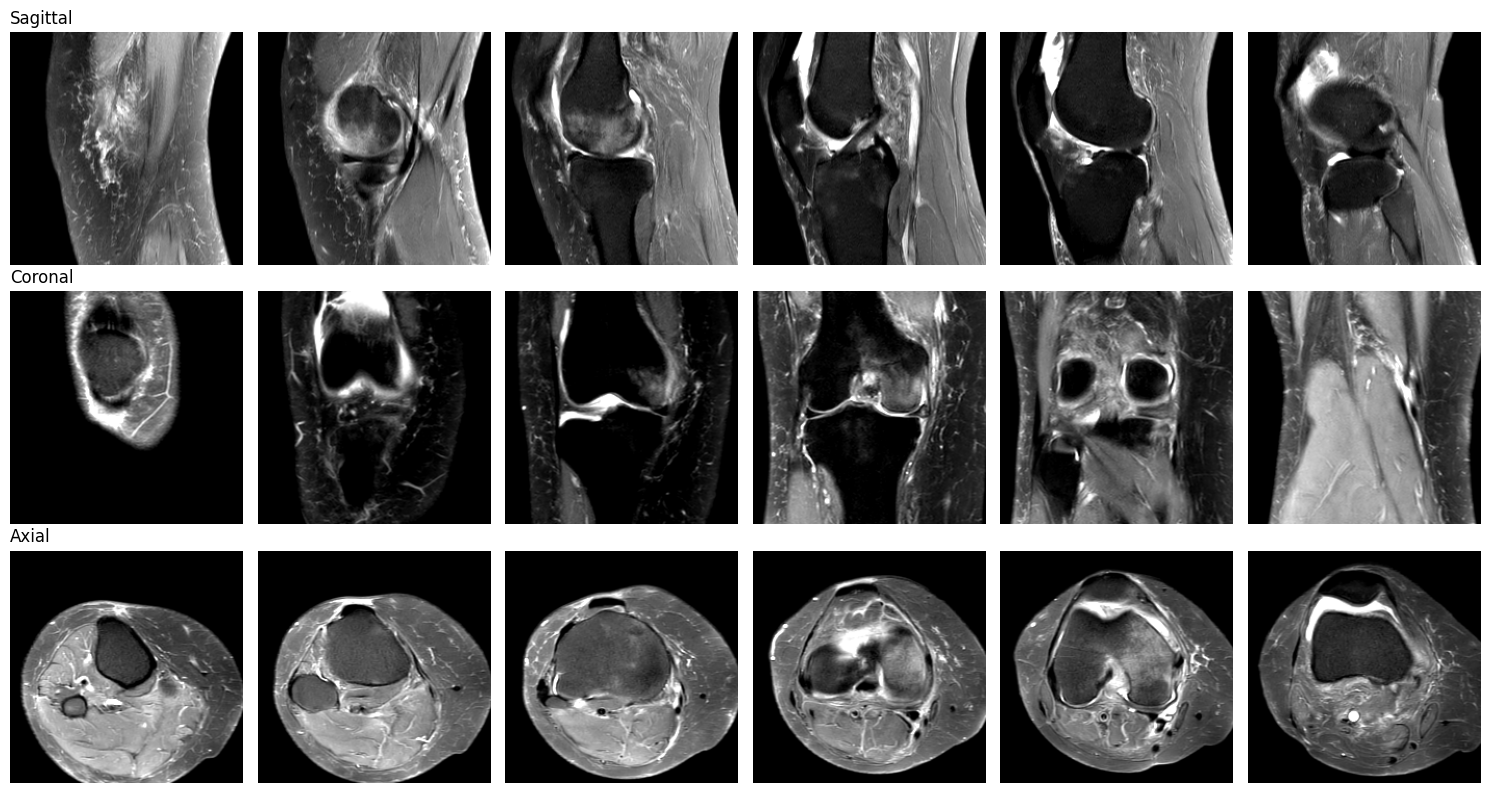

In [12]:
example = chosen.iloc[0]

start = time.time()
volume = load_study(example["StudyInstanceUID"], example, f"{COMP}/train_series")
print(f"{time.time() - start:.1f} seconds for one study, shape {volume.shape}")

fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for plane in range(3):
    for col in range(6):
        axes[plane, col].imshow(volume[plane, col * 2], cmap="gray")
        axes[plane, col].axis("off")
    axes[plane, 0].set_title(PLANES[plane], loc="left")

plt.tight_layout()
plt.show()

**Check 4.** You should see a knee. Black rows mean that study has no series for
that plane, which is normal for some studies.

## 6. Cache the studies

Reading DICOM is the slow part: about 1.5 hours for all ~4,350 studies. So we do it **once**:

1. The first full run reads the DICOMs and saves the arrays to `/kaggle/working`.
2. Open that version -> **Output** -> **New Dataset**, and name it exactly **`knee-train-cache`**.
3. **Add Input** -> Datasets -> your `knee-train-cache`.

From then on this cell reads the saved arrays in about a minute. Only the images are cached:
the labels are rebuilt from the reports every run, so label changes still work without
re-caching. **RAM.** All studies at 224 px are about 8 GB. The array is written straight to a file in
`/kaggle/working` instead of being held in RAM, and read back as needed. That keeps the notebook
far below Kaggle's ~30 GB limit, and the same file becomes the cache. The cell stops with a clear
message if the settings would need more than the 20 GB Kaggle saves.

The test set is never cached - Kaggle swaps in the hidden test set when scoring.

**v4:** if you have not made the dataset yet, open the v3 run that scored 0.861 -> **Output** ->
**New Dataset** -> name it `knee-train-cache`. v4 uses that cache as it is (same settings).
For E5 (288 px) make a second dataset called `knee-train-cache-288` the same way.

A cache made by v2 does not fit v3 (v3 mirrors left knees), and the same goes for changing
`SLICES_PER_PLANE`, `IMG_SIZE` or `CROP_MM`. The cell
notices, reads the DICOMs again, and saves a new cache to make a new dataset from.

In [13]:
# Kaggle mounts your dataset in one of these two places
# Any team member's knee-train-cache dataset works, whoever owns it
CACHE_CANDIDATES = (sorted(glob.glob("/kaggle/input/datasets/*/knee-train-cache*"))
                    + ["/kaggle/input/knee-train-cache", "/kaggle/input/knee-train-cache-288"])
print("cache folders found:", CACHE_CANDIDATES[:-2])
CACHE_KEY = f"slices={SLICES_PER_PLANE} size={IMG_SIZE} crop={CROP_MM} right-knees"


def cache_fits(folder):
    try:
        return open(f"{folder}/cache_key.txt").read() == CACHE_KEY
    except OSError:
        return False


CACHE_DIR = next((p for p in CACHE_CANDIDATES if cache_fits(p)), None)

# The 58 expert studies are never trained on. They are our honest score.
gold_ids = set(labelled["StudyInstanceUID"])
gold = labelled.merge(chosen, on="StudyInstanceUID").reset_index(drop=True)
y_gold = gold[LABELS].values.astype("float32")

if CACHE_DIR and open(f"{CACHE_DIR}/cache_key.txt").read() == CACHE_KEY:
    start = time.time()
    cached_ids = pd.read_csv(f"{CACHE_DIR}/train_uids.csv")["StudyInstanceUID"][:TRAIN_STUDIES]
    # mmap: the array stays in the file and is read as needed, so it does not have to fit in RAM
    volumes = np.load(f"{CACHE_DIR}/train_volumes.npy", mmap_mode="r")[:len(cached_ids)]
    # Copy into RAM when there is room: 5 folds read every study many times, and RAM is
    # much faster than the input disk. 224 px is about 8 GB, 288 px about 13 GB.
    if volumes.nbytes < 0.6 * psutil.virtual_memory().available:
        volumes = np.ascontiguousarray(volumes)
    gold_volumes = np.load(f"{CACHE_DIR}/gold_volumes.npy")

    # only the images come from the cache, the labels are this run's labels
    usable = pd.DataFrame({"StudyInstanceUID": cached_ids}).merge(labels, on="StudyInstanceUID", how="left")
    assert list(pd.read_csv(f"{CACHE_DIR}/gold_uids.csv")["StudyInstanceUID"]) == list(gold["StudyInstanceUID"])
    print("read from cache:", CACHE_DIR)
    print(f"loaded in {(time.time() - start) / 60:.1f} min")

else:
    print("no cache with these settings is attached, reading the DICOMs (about 4 hours)")

    usable = labels[~labels["StudyInstanceUID"].isin(gold_ids)].merge(chosen, on="StudyInstanceUID")
    usable = usable[usable[PLANES].notna().any(axis=1)]
    usable = usable[usable[LABELS].notna().any(axis=1)]    # a report that mentions nothing teaches nothing
    usable = usable.sample(min(TRAIN_STUDIES, len(usable)), random_state=SEED).reset_index(drop=True)

    print("studies to load:", len(usable))

    # Kaggle gives about 30 GB of RAM and saves at most 20 GB of /kaggle/working.
    shape = (len(usable), 3, SLICES_PER_PLANE, IMG_SIZE, IMG_SIZE)
    need_gb = np.prod(shape) / 1e9
    print(f"training images need {need_gb:.1f} GB")
    assert need_gb < 19, "too big for /kaggle/working: lower TRAIN_STUDIES, IMG_SIZE or SLICES_PER_PLANE"

    start = time.time()
    # Written straight into a file on disk, not into RAM. That file is also next run's cache,
    # and Linux keeps it in memory while there is room, so training is not slowed down.
    volumes = np.lib.format.open_memmap("/kaggle/working/train_volumes.npy", mode="w+",
                                        dtype=np.uint8, shape=shape)
    for i in range(len(usable)):
        row = usable.iloc[i]
        volumes[i] = load_study(row["StudyInstanceUID"], row, f"{COMP}/train_series")
        if (i + 1) % 500 == 0:
            print(f"  {i + 1}/{len(usable)}   {(time.time() - start) / 60:.1f} min")

    gold_volumes = np.stack([load_study(r["StudyInstanceUID"], r, f"{COMP}/train_series")
                             for _, r in gold.iterrows()])
    print(f"loaded in {(time.time() - start) / 60:.1f} min")

    # Save for next time. Make a dataset called knee-train-cache from this version's output.
    volumes.flush()                     # train_volumes.npy is already on disk
    np.save("/kaggle/working/gold_volumes.npy", gold_volumes)
    usable[["StudyInstanceUID"]].to_csv("/kaggle/working/train_uids.csv", index=False)
    gold[["StudyInstanceUID"]].to_csv("/kaggle/working/gold_uids.csv", index=False)
    open("/kaggle/working/cache_key.txt", "w").write(CACHE_KEY)
    print("saved the cache to /kaggle/working")

print("array:", volumes.shape, volumes.dtype, f"{volumes.nbytes / 1e6:.0f} MB")
print("gold studies:", len(gold_volumes))
print(f"RAM in use by this notebook: {psutil.Process().memory_info().rss / 1e9:.1f} GB")

cache folders found: ['/kaggle/input/datasets/tanishakeshav/knee-train-cache']
read from cache: /kaggle/input/datasets/tanishakeshav/knee-train-cache
loaded in 0.0 min
array: (4349, 3, 12, 224, 224) uint8 7856 MB
gold studies: 58
RAM in use by this notebook: 1.1 GB


## 7. Targets and weights

`y` is what we train towards: the language model's score for each finding (soft, between 0 and 1).
`mask` is how much each finding counts in the loss: the language model's confidence. A clear
"yes" or "no" counts fully, a finding the report never mentions counts almost nothing.

The loss is the same masked binary cross-entropy as before - it already accepts soft targets and
weights between 0 and 1.

**v4 - folds.** Every study is put in one of 5 folds. Fold model 1 trains on folds 2-5 and is
checked on fold 1, and so on. Each study is one row, so a study (and its series) is never in
training and checking at the same time. The 58 gold studies are in no fold at all.

**v4 - `loss_mask`.** With `LOSS = "per_finding"` each finding's weights are scaled so that every
finding counts the same in total. Synovitis (clear in only 19% of reports) and Fracture (40%)
otherwise count much less than ACL or Effusion.

In [14]:
y = usable[LABELS].values.astype("float32")
mask = usable[CONF].values.astype("float32")

print("average weight per finding (how often the report clearly says yes or no):")
print(pd.Series(mask.mean(axis=0), index=LABELS).round(2).to_string())

# Each study goes to one fold. N_FOLDS = 1 keeps v3's single 10% check set.
rng = np.random.default_rng(SEED)
n_splits = N_FOLDS if N_FOLDS > 1 else 10
fold_of = rng.permutation(len(usable)) % n_splits
assert not set(usable["StudyInstanceUID"]) & gold_ids, "a gold study is in the training data"

for fold in range(N_FOLDS):
    print(f"fold {fold}: train {(fold_of != fold).sum()}   valid {(fold_of == fold).sum()}")

# Only the training loss uses loss_mask. Scores always use the plain mask.
loss_mask = mask.copy()
if LOSS == "per_finding":
    finding_weight = np.clip(mask.mean() / np.maximum(mask.mean(axis=0), 1e-3), 1.0, 3.0)
    loss_mask = mask * finding_weight.astype("float32")
    print("\nextra weight per finding:")
    print(pd.Series(finding_weight, index=LABELS).round(2).to_string())

average weight per finding (how often the report clearly says yes or no):
ACL                 0.81
MCL                 0.79
Medial Meniscus     0.86
Lateral Meniscus    0.80
Medial OA           0.68
Lateral OA          0.61
PF OA               0.75
Effusion            0.83
Synovitis           0.19
Baker's             0.51
Contusion           0.71
Fracture            0.40
fold 0: train 3479   valid 870
fold 1: train 3479   valid 870
fold 2: train 3479   valid 870
fold 3: train 3479   valid 870
fold 4: train 3480   valid 869


## 8. The model

A study is 3 planes of 12 slices. We group the slices in threes, so each group looks like a normal colour image with 3 channels. That gives 12 small images per study.

The same ResNet34 looks at all 12. Then we combine them into one vector per study and one linear layer turns that into 12 numbers.

**About the weights.** Internet stays off, so the ImageNet weights come from a public Kaggle dataset:
*Add Input -> Datasets ->* search **PyTorch ResNet-(18, 34, 50, 101, 152) Pretrained** (by Wei Hao Khoong).
Nothing to upload. Starting from random weights is why the first version scored 0.55:
300 studies are not enough to learn what an edge or texture is.

Pretrained weights expect images scaled the way ImageNet was scaled, so the model does that
scaling itself at the start of `forward`.

**No random mirroring any more.** v2 randomly mirrored knees during training and averaged each
prediction with its mirror image. Now that every knee is turned into a right knee (section 5),
mirroring would undo exactly that, so v3 removes it.

**v4 - `POOLING = "attention"`.** Mean and max do not know *which* image a feature came from. But
sagittal slices run from the inner to the outer side of the knee, so "where" tells medial from
lateral. The attention version adds a learned position to each of the 12 images, and each
finding learns which images to look at.

**v4 - `AUGMENT = True`.** The same small rotation (up to 10 degrees), zoom (0.9-1.1) and shift (up
to 5%) for every slice of one plane, plus a small contrast change. Never a flip: every knee is
already a right knee, and a flip would swap medial and lateral.

In [15]:
# Found in the imports cell, right at the start of the notebook
print("weights file:", WEIGHTS_PATH)

weights file: /kaggle/input/datasets/khoongweihao/pytorch-resnet18-34-50-101-152-pretrained/resnet34.pth/resnet34.pth


In [16]:
def augment_plane(stack):
    """Same small rotation, zoom and shift for every slice of one plane. Never a flip."""
    n, h, w = stack.shape
    angle = np.random.uniform(-10, 10)
    scale = np.random.uniform(0.9, 1.1)
    shift_x, shift_y = np.random.uniform(-0.05, 0.05, size=2) * (w, h)

    matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    matrix[:, 2] += (shift_x, shift_y)
    return np.stack([cv2.warpAffine(s, matrix, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)
                     for s in stack])


class StudyDataset(Dataset):
    def __init__(self, volumes, y, mask, training):
        self.volumes = volumes
        self.y = y
        self.mask = mask
        self.training = training

    def __len__(self):
        return len(self.volumes)

    def __getitem__(self, i):
        volume = self.volumes[i]                      # (3, 12, H, W)
        planes, slices, h, w = volume.shape

        if self.training and AUGMENT:
            volume = np.stack([augment_plane(p) if np.random.rand() < 0.7 else p for p in volume])

        # 3 planes x 4 groups of 3 slices = 12 images
        windows = volume.reshape(planes * (slices // 3), 3, h, w).astype("float32") / 255.0

        if self.training:
            if AUGMENT and np.random.rand() < 0.5:
                windows = windows ** np.random.uniform(0.8, 1.25)   # small contrast change
            windows = windows * np.random.uniform(0.9, 1.1)          # small brightness change

        return (torch.from_numpy(np.ascontiguousarray(windows, dtype="float32")),
                torch.from_numpy(self.y[i]),
                torch.from_numpy(self.mask[i]))

In [17]:
class KneeNet(nn.Module):
    def __init__(self):
        super().__init__()
        # pretrained=False because internet is off. The ImageNet weights are loaded from WEIGHTS_PATH below.
        self.encoder = timm.create_model(BACKBONE, pretrained=False, num_classes=0)
        features = self.encoder.num_features
        windows = len(PLANES) * (SLICES_PER_PLANE // 3)

        if POOLING == "attention":
            self.position = nn.Parameter(torch.zeros(1, windows, features))   # where each image is
            self.attention = nn.Linear(features, len(LABELS))                 # one attention per finding
            self.head = nn.Linear(features, len(LABELS))
        else:
            self.head = nn.Linear(features * 2, len(LABELS))

        if WEIGHTS_PATH:
            # the file is the official torchvision download, saved in the old format that
            # weights_only=True (the default since PyTorch 2.6) refuses to read
            payload = torch.load(WEIGHTS_PATH, map_location="cpu", weights_only=False)

            if isinstance(payload, nn.Module):
                state = payload.state_dict()
            elif isinstance(payload, dict):
                state = payload.get("state_dict", payload)
                if isinstance(state, dict) and "model" in state and isinstance(state["model"], dict):
                    state = state["model"]
            else:
                raise ValueError("Unsupported checkpoint format")

            if not isinstance(state, dict):
                raise ValueError("Checkpoint does not contain a state_dict")

            cleaned = {}
            for key, value in state.items():
                key = str(key)
                if key.startswith("fc."):
                    continue    # ImageNet's 1000-class layer, we have our own head
                for prefix in ("module.", "model."):
                    if key.startswith(prefix):
                        key = key[len(prefix):]
                cleaned[key] = value

            # Files saved before PyTorch 0.4.1 have no BatchNorm step counters (num_batches_tracked).
            # They are just counters, not learned weights, so take them from the new model.
            for key, value in self.encoder.state_dict().items():
                if key.endswith("num_batches_tracked") and key not in cleaned:
                    cleaned[key] = value

            full_keys = set(self.state_dict().keys())
            encoder_keys = set(self.encoder.state_dict().keys())
            cleaned_keys = set(cleaned.keys())

            full_overlap = len(full_keys & cleaned_keys)
            encoder_overlap = len(encoder_keys & cleaned_keys)

            if full_overlap >= len(full_keys) * 0.95:
                report = self.load_state_dict(cleaned, strict=True)
                print("loaded full model weights: strict=True")
            elif encoder_overlap >= len(encoder_keys) * 0.95:
                report = self.encoder.load_state_dict(cleaned, strict=True)
                print("loaded encoder weights: strict=True; classification head remains initialized")
            else:
                raise ValueError(
                    f"Incompatible checkpoint: full overlap {full_overlap}/{len(full_keys)}, "
                    f"encoder overlap {encoder_overlap}/{len(encoder_keys)}"
                )

        # ImageNet scaling, because that is what the pretrained weights expect
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):                             # x is (batch, 12, 3, H, W)
        batch, windows = x.shape[:2]

        x = (x.flatten(0, 1) - self.mean) / self.std
        features = self.encoder(x).view(batch, windows, -1)

        if POOLING == "attention":
            features = features + self.position
            weights = self.attention(features).float().softmax(dim=1)          # (batch, 12 images, 12 findings)
            pooled = torch.einsum("bwk,bwf->bkf", weights, features.float())   # one summary per finding
            return (pooled * self.head.weight).sum(-1) + self.head.bias

        # mean finds things spread through the joint, max finds things on one slice
        pooled = torch.cat([features.mean(1), features.max(1).values], dim=1)
        return self.head(pooled)


def masked_bce(logits, target, mask):
    losses = nn.functional.binary_cross_entropy_with_logits(logits, target, reduction="none")
    return (losses * mask).sum() / mask.sum().clamp(min=1)

## 9. Train

Five fold models are trained one after another. For each epoch you see the loss, `valid` (this
fold's check set, scored against the report labels) and `gold` (the 58 expert studies).

**What changed from v3.** v3 kept the epoch with the best `gold`. That picks the luckiest epoch on
58 studies, so the gold number looked a little better than it really was. v4 picks each fold's
epoch by its own `valid` score. `gold` is only watched, so it stays an honest test.

At the end you get:

- **OOF** - every study predicted by the fold model that never saw it (about 4,350 studies, report labels).
- **gold** - the averaged 5 models on the 58 expert studies.
- a **`RESULT`** line to copy into the table in section 12.

The submission cells below use `model`, which is now the 5 models averaged. They are unchanged.

In [18]:
TRAIN_WORKERS = 2        # Kaggle gives 4 CPU cores; 2 prepare batches while the GPU trains


def make_loader(index, training):
    data = StudyDataset(volumes, y, loss_mask if training else mask, training)
    return DataLoader(torch.utils.data.Subset(data, index), batch_size=BATCH_SIZE,
                      shuffle=training, drop_last=training,
                      num_workers=TRAIN_WORKERS if training else 0,
                      pin_memory=(DEVICE == "cuda"))


gold_loader = DataLoader(
    StudyDataset(gold_volumes, y_gold, np.ones_like(y_gold), False),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


def predict(net, loader):
    net.eval()
    out = []

    with torch.no_grad(), torch.amp.autocast("cuda", enabled=(DEVICE == "cuda")):
        for x, _, _ in loader:
            out.append(torch.sigmoid(net(x.to(DEVICE))).float().cpu().numpy())

    return np.concatenate(out)


def train_fold(fold):
    torch.manual_seed(SEED + fold)
    train_idx, valid_idx = np.where(fold_of != fold)[0], np.where(fold_of == fold)[0]
    train_loader, valid_loader = make_loader(train_idx, True), make_loader(valid_idx, False)

    net = KneeNet().to(DEVICE)
    optimiser = torch.optim.AdamW(net.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    # warm up for the first 10% of steps so the pretrained weights are not shaken, then slowly lower
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimiser, max_lr=LEARNING_RATE, total_steps=EPOCHS * len(train_loader), pct_start=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))

    best_valid, best_state, best_pred = -1.0, None, None

    for epoch in range(EPOCHS):
        net.train()
        running = 0.0

        for x, target, m in train_loader:
            x, target, m = x.to(DEVICE), target.to(DEVICE), m.to(DEVICE)

            with torch.amp.autocast("cuda", enabled=(DEVICE == "cuda")):
                loss = masked_bce(net(x), target, m)

            scaler.scale(loss).backward()
            scaler.step(optimiser)
            scaler.update()
            optimiser.zero_grad(set_to_none=True)
            scheduler.step()

            running += loss.item()

        valid_pred = predict(net, valid_loader)
        score = macro_auc(y[valid_idx], valid_pred, (mask[valid_idx] > 0.5).astype("float32"))["MACRO"]
        gold_score = macro_auc(y_gold, predict(net, gold_loader))["MACRO"]
        print(f"epoch {epoch}   loss {running / len(train_loader):.4f}   valid {score:.3f}   gold {gold_score:.3f}")

        # chosen on this fold's own check set; gold is only watched
        if score > best_valid:
            best_valid, best_pred = score, valid_pred
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}

    net.load_state_dict(best_state)
    return net, valid_idx, best_pred


print(len(make_loader(np.where(fold_of != 0)[0], True)), "batches per epoch")

434 batches per epoch


In [19]:
class FoldEnsemble(nn.Module):
    """All fold models as one model. Averages their outputs before the sigmoid."""

    def __init__(self, models):
        super().__init__()
        self.models = nn.ModuleList(models)

    def forward(self, x):
        return torch.stack([m(x) for m in self.models]).mean(0)


start = time.time()
fold_models = []
oof = np.full(y.shape, np.nan, dtype="float32")

for fold in range(N_FOLDS):
    print(f"\n--- fold {fold + 1} of {N_FOLDS} ---")
    net, valid_idx, valid_pred = train_fold(fold)
    fold_models.append(net)
    oof[valid_idx] = valid_pred
    print(f"{(time.time() - start) / 60:.1f} min so far")

# the submission cells below use `model`
model = FoldEnsemble(fold_models).to(DEVICE)
print(f"\ntrained in {(time.time() - start) / 60:.1f} min")

seen = ~np.isnan(oof[:, 0])
oof_scores = macro_auc(y[seen], oof[seen], (mask[seen] > 0.5).astype("float32"))
print("\nOOF score per finding (each study predicted by a model that never saw it, report labels):")
show_scores(oof_scores)

gold_scores = macro_auc(y_gold, predict(model, gold_loader))
print("\ngold score per finding (58 expert studies, all fold models averaged):")
show_scores(gold_scores)

# saved for later: comparing runs and building an ensemble of different settings
tag = f"f{N_FOLDS}_{POOLING}_{LOSS}_aug{int(AUGMENT)}_{BACKBONE}_{IMG_SIZE}_{int(CROP_MM)}"
pd.DataFrame(oof[seen], columns=LABELS).assign(
    StudyInstanceUID=usable["StudyInstanceUID"].values[seen]).to_csv(f"/kaggle/working/oof_{tag}.csv", index=False)
torch.save({f"fold{i}": m.state_dict() for i, m in enumerate(fold_models)}, "/kaggle/working/knee_model.pt")

print(f"\nRESULT  {tag}   OOF {oof_scores['MACRO']:.4f}   gold {gold_scores['MACRO']:.4f}")


--- fold 1 of 5 ---
loaded encoder weights: strict=True; classification head remains initialized
epoch 0   loss 0.6244   valid 0.776   gold 0.730
epoch 1   loss 0.5801   valid 0.839   gold 0.815
epoch 2   loss 0.5427   valid 0.848   gold 0.833
epoch 3   loss 0.4957   valid 0.859   gold 0.850
epoch 4   loss 0.4534   valid 0.862   gold 0.842
11.3 min so far

--- fold 2 of 5 ---
loaded encoder weights: strict=True; classification head remains initialized
epoch 0   loss 0.6248   valid 0.777   gold 0.733
epoch 1   loss 0.5805   valid 0.816   gold 0.801
epoch 2   loss 0.5434   valid 0.838   gold 0.837
epoch 3   loss 0.4941   valid 0.849   gold 0.853
epoch 4   loss 0.4497   valid 0.849   gold 0.855
20.3 min so far

--- fold 3 of 5 ---
loaded encoder weights: strict=True; classification head remains initialized
epoch 0   loss 0.6258   valid 0.784   gold 0.764
epoch 1   loss 0.5837   valid 0.822   gold 0.795
epoch 2   loss 0.5464   valid 0.839   gold 0.833
epoch 3   loss 0.4996   valid 0.852  

**Check 5.** In every fold the loss must go down between epochs, and `gold` should be clearly
above 0.5 after the first epoch.

Write down the `RESULT` line. **OOF** uses about 4,350 studies, so it is steady; **gold** uses only
58, so it can move by about 0.01-0.02 by chance. Keep a change when OOF goes up and gold does not
clearly drop, then confirm with the leaderboard.

## 10. Predict the test set

Kaggle replaces the public three-study example with the hidden test set during scoring. The code below therefore uses the test IDs as the source of truth and does not use the public `sample_submission.csv` rows to determine how many predictions to make.


In [20]:
test = pd.read_csv(f"{COMP}/test.csv")
test_series = pd.read_csv(f"{COMP}/test_series.csv")

assert "StudyInstanceUID" in test.columns
assert test["StudyInstanceUID"].notna().all()
assert test["StudyInstanceUID"].astype(str).is_unique
assert os.path.isdir(f"{COMP}/test_series"), "test_series directory not found"

required_test_series_columns = {
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "Fluid_Sensitive",
    "Fat_Suppression",
    "Anatomical_Plane",
}
assert required_test_series_columns.issubset(test_series.columns)

test["StudyInstanceUID"] = test["StudyInstanceUID"].astype(str)
test_series["StudyInstanceUID"] = test_series["StudyInstanceUID"].astype(str)
test_series["SeriesInstanceUID"] = test_series["SeriesInstanceUID"].astype(str)

test_chosen = pick_series(test_series).set_index("StudyInstanceUID")

DICOM_READ_ERRORS = 0
SERIES_READ_ERRORS = 0
STUDY_READ_ERRORS = 0

missing_series_rows = set(test["StudyInstanceUID"]) - set(test_series["StudyInstanceUID"])
print("test studies:", len(test))
print("test series rows:", len(test_series))
print("studies missing from test_series.csv:", len(missing_series_rows))

# Missing descriptors are handled later as all-zero image input rather than aborting a hidden run.

test studies: 3
test series rows: 15
studies missing from test_series.csv: 0


In [21]:
# The hidden test set is larger than the public three-study example.
# Do not run a separate serial prediction pass here: it would read the same DICOMs twice.

test = pd.read_csv(f"{COMP}/test.csv")
test_series = pd.read_csv(f"{COMP}/test_series.csv")

assert "StudyInstanceUID" in test.columns
assert test["StudyInstanceUID"].notna().all()
assert test["StudyInstanceUID"].is_unique
assert os.path.isdir(f"{COMP}/test_series"), "test_series directory not found"

required_test_series_columns = {
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "Fluid_Sensitive",
    "Fat_Suppression",
    "Anatomical_Plane",
}
assert required_test_series_columns.issubset(test_series.columns)

test_chosen = pick_series(test_series).set_index("StudyInstanceUID")

missing_series_rows = set(test["StudyInstanceUID"]) - set(test_series["StudyInstanceUID"])
assert not missing_series_rows, "Some test studies have no test_series.csv entry."

print("test studies:", len(test))
print("test series rows:", len(test_series))


test studies: 3
test series rows: 15


**Check 6.** The final inference pass below is the only test prediction pass. During local editing it processes the public example; during Kaggle scoring `test.csv`, `test_series.csv`, and `test_series/` are replaced by the hidden test data.


In [22]:
class TestStudyDataset(Dataset):
    def __init__(self, study_uids, chosen_df, root):
        self.study_uids = study_uids
        self.chosen_df = chosen_df
        self.root = root

    def __len__(self):
        return len(self.study_uids)

    def __getitem__(self, idx):
        uid = str(self.study_uids[idx])

        try:
            row = self.chosen_df.loc[uid] if uid in self.chosen_df.index else {}
            volume = load_study(uid, row, self.root)

            if not isinstance(volume, np.ndarray):
                raise ValueError("load_study did not return a numpy array")

            expected_shape = (3, SLICES_PER_PLANE, IMG_SIZE, IMG_SIZE)
            if volume.shape != expected_shape:
                raise ValueError(f"unexpected volume shape: {volume.shape}")

            volume = np.nan_to_num(volume, nan=0, posinf=0, neginf=0).astype(np.uint8)
            planes, slices, h, w = volume.shape
            windows = volume.reshape(
                planes * (slices // 3),
                3,
                h,
                w,
            ).astype("float32") / 255.0

            windows = np.nan_to_num(windows, nan=0.0, posinf=1.0, neginf=0.0)
            return torch.from_numpy(windows), uid

        except Exception as e:
            # A single problematic hidden study must not prevent submission.csv from being written.
            print(f"warning: fallback zero volume for study {uid}: {type(e).__name__}: {e}")
            windows = np.zeros(
                (len(PLANES) * (SLICES_PER_PLANE // 3), 3, IMG_SIZE, IMG_SIZE),
                dtype="float32",
            )
            return torch.from_numpy(windows), uid


# Conservative settings for hidden scoring. workers=0 avoids multiprocessing/shared-memory
# failures and makes all DICOM errors recoverable in the main process.
TEST_BATCH_SIZE = 2
TEST_WORKERS = 0

study_uids = test["StudyInstanceUID"].astype(str).tolist()

test_dataset = TestStudyDataset(
    study_uids,
    test_chosen,
    f"{COMP}/test_series"
)

assert len(test_dataset) == len(test)

test_loader = DataLoader(
    test_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=TEST_WORKERS,
    pin_memory=(DEVICE == "cuda"),
)

model.eval()
prediction_map = {}
fallback_batch_count = 0
start = time.time()

with torch.inference_mode():
    for batch_idx, (x, uids) in enumerate(test_loader):
        try:
            x = x.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=(DEVICE == "cuda")):
                pred = torch.sigmoid(model(x))

            pred = pred.float().cpu().numpy()
            pred = np.nan_to_num(pred, nan=0.5, posinf=1.0, neginf=0.0)
            pred = np.clip(pred, 0.0, 1.0)

            for uid, row_pred in zip(uids, pred):
                prediction_map[str(uid)] = row_pred.astype("float32")

        except Exception as e:
            # If a whole GPU batch ever fails, keep the submission alive by assigning neutral
            # predictions to that batch. This is deliberately a last-resort fallback.
            fallback_batch_count += 1
            print(f"warning: fallback 0.5 predictions for batch {batch_idx}: {type(e).__name__}: {e}")
            for uid in uids:
                prediction_map[str(uid)] = np.full(len(LABELS), 0.5, dtype="float32")
            if DEVICE == "cuda":
                torch.cuda.empty_cache()

        done = min((batch_idx + 1) * TEST_BATCH_SIZE, len(test_dataset))
        if batch_idx == 0 or done % (TEST_BATCH_SIZE * 10) == 0 or done == len(test_dataset):
            elapsed = time.time() - start
            per_study = elapsed / max(done, 1)
            eta = per_study * (len(test_dataset) - done)
            print(
                f"{done}/{len(test_dataset)} studies | "
                f"{elapsed/60:.1f} min elapsed | "
                f"ETA {eta/60:.1f} min"
            )

# Build predictions in exactly the test.csv order. Missing UIDs receive neutral predictions.
pred_rows = []
missing_prediction_uids = []
for uid in study_uids:
    row_pred = prediction_map.get(uid)
    if row_pred is None:
        missing_prediction_uids.append(uid)
        row_pred = np.full(len(LABELS), 0.5, dtype="float32")
    pred_rows.append(row_pred)

predictions = np.asarray(pred_rows, dtype="float32")
predictions = np.nan_to_num(predictions, nan=0.5, posinf=1.0, neginf=0.0)
predictions = np.clip(predictions, 0.0, 1.0)

assert predictions.shape == (len(test), len(LABELS))

print("prediction rows:", len(predictions))
print("missing prediction UIDs recovered with 0.5:", len(missing_prediction_uids))
print("fallback inference batches:", fallback_batch_count)


def write_submission(pred, studies, test_df, path):
    if len(pred) != len(studies):
        raise ValueError("prediction rows and StudyInstanceUID rows have different lengths")

    ranked = pd.DataFrame(pred, columns=LABELS).rank(pct=True, method="average")
    pred_frame = ranked.copy()
    pred_frame.insert(0, "StudyInstanceUID", [str(x) for x in studies])

    # The actual test.csv is authoritative for hidden IDs and row order.
    sub = test_df[["StudyInstanceUID"]].copy()
    sub["StudyInstanceUID"] = sub["StudyInstanceUID"].astype(str)
    sub = sub.merge(
        pred_frame,
        on="StudyInstanceUID",
        how="left",
        validate="one_to_one"
    )

    # Match the robust pattern used by successful public notebooks: no hidden study is
    # allowed to remain without a valid prediction row.
    sub[LABELS] = sub[LABELS].fillna(0.5)
    sub = sub[["StudyInstanceUID"] + LABELS]
    sub.to_csv(path, index=False)
    return sub

def validate_submission(path, test_df, tag="submission"):
    frame = pd.read_csv(path)
    expected = ["StudyInstanceUID"] + LABELS

    if list(frame.columns) != expected:
        raise ValueError(f"{tag}: columns differ from the competition contract")

    if len(frame) != len(test_df):
        raise ValueError(f"{tag}: row count differs from test.csv")

    if not frame["StudyInstanceUID"].astype(str).is_unique:
        raise ValueError(f"{tag}: StudyInstanceUID uniqueness failed")

    if set(frame["StudyInstanceUID"].astype(str)) != set(test_df["StudyInstanceUID"].astype(str)):
        raise ValueError(f"{tag}: StudyInstanceUID set differs from test.csv")

    values = frame[LABELS].apply(pd.to_numeric, errors="coerce").to_numpy(np.float64)

    if not np.isfinite(values).all():
        raise ValueError(f"{tag}: non-finite prediction")

    if values.min() < 0.0 or values.max() > 1.0:
        raise ValueError(f"{tag}: prediction outside [0, 1]")

    return frame


WORKDIR = "/kaggle/working"
os.makedirs(WORKDIR, exist_ok=True)
os.chdir(WORKDIR)
submission_path = "submission.csv"
submission = write_submission(predictions, study_uids, test, submission_path)

checked = validate_submission(submission_path, test, "final")

# Read back the exact file that Kaggle will inspect.
checked = pd.read_csv(submission_path)

print("saved submission.csv:", checked.shape)
print("absolute path:", os.path.abspath(submission_path))
print("✅ submission.csv is valid")
print(checked.head())

2/3 studies | 0.1 min elapsed | ETA 0.1 min
3/3 studies | 0.1 min elapsed | ETA 0.0 min
prediction rows: 3
missing prediction UIDs recovered with 0.5: 0
fallback inference batches: 0
saved submission.csv: (3, 13)
absolute path: /kaggle/working/submission.csv
✅ submission.csv is valid
                                    StudyInstanceUID       ACL       MCL  \
0  1.2.826.0.1.3680043.8.498.10047035057544427318...  0.666667  1.000000   
1  1.2.826.0.1.3680043.8.498.10062861783145312629...  1.000000  0.666667   
2  1.2.826.0.1.3680043.8.498.10067514707072572280...  0.333333  0.333333   

   Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA     PF OA  \
0         1.000000          0.333333   0.333333    0.333333  0.333333   
1         0.333333          1.000000   1.000000    1.000000  1.000000   
2         0.666667          0.666667   0.666667    0.666667  0.666667   

   Effusion  Synovitis   Baker's  Contusion  Fracture  
0  0.666667   0.666667  1.000000   0.666667  0.333333  
1  1.

In [23]:
# Final submission validation.
# This mirrors the competition contract and validates the exact file on disk.
os.chdir("/kaggle/working")
validate_submission("submission.csv", test, "final on-disk")

assert os.path.isfile("/kaggle/working/submission.csv"), "submission.csv was not created"
assert os.path.getsize("/kaggle/working/submission.csv") > 0, "submission.csv is empty"

print("DICOM read fallbacks:", DICOM_READ_ERRORS)
print("Study read fallbacks:", STUDY_READ_ERRORS)
print("✅ FINAL CHECK PASSED")
print("path:", "/kaggle/working/submission.csv")
print("shape:", pd.read_csv("/kaggle/working/submission.csv").shape)
print("size:", os.path.getsize("/kaggle/working/submission.csv"), "bytes")

DICOM read fallbacks: 0
Study read fallbacks: 0
✅ FINAL CHECK PASSED
path: /kaggle/working/submission.csv
shape: (3, 13)
size: 830 bytes


## 11. Submission checklist

| Check | Required | This notebook |
|---|---|---|
| Submission through Notebook | Yes | ✅ |
| CPU Notebook <= 9 hours | Yes | ✅ notebook is designed below this limit |
| GPU Notebook <= 9 hours | Yes | ✅ notebook is designed below this limit |
| Internet disabled | Yes | ✅ no network/download code |
| External public data | Allowed | ✅ ImageNet ResNet34 weights, LLM-read report labels (both public Kaggle datasets) |
| Output filename | `submission.csv` | ✅ |
| One row per hidden test study | Yes | ✅ built from hidden `test.csv` |
| Twelve target columns | Yes | ✅ |
| Missing predictions | Must not remain missing | ✅ filled with 0.5 |
| Duplicate IDs | Not allowed | ✅ checked |
| Non-finite values | Not allowed | ✅ checked |
| Values in confidence range | Required | ✅ checked |

Kaggle will rerun the notebook privately with the hidden test files. The notebook therefore does not rely on the three-row public test set for submission size or IDs.

## 12. Project report: what changed, why, and what it did

The score is the **mean of 12 ROC-AUCs**, one per finding. 0.5 = guessing, 1.0 = perfect.
`gold` below means macro AUC on the 58 expert-labelled training studies, which are never trained on.

### Stage 1 - the first submission: 0.55

| What | Setting |
|---|---|
| Model | ResNet34 with **random weights** (`pretrained=False`, because internet is off) |
| Data | 300 studies, 4 epochs, batch 4 |
| Labels | keyword search; "small / mild" counted as **absent**; `normal` also matched inside `abnormal` |
| Validation | 20% split scored against our own keyword labels |

The submission chain worked (hidden test read, 1,300 rows written, file validated), but the
model learned almost nothing: 228 training studies and 228 weight updates cannot teach a
21-million-weight network what an edge is. Validation wandered between 0.49 and 0.59 and the
leaderboard gave **0.55**. Scoring took over an hour because Kaggle re-runs the whole notebook on
about 1,300 hidden studies, not the 3 example ones.

### Stage 2 - v2: 0.55 -> 0.711

| Change | Why |
|---|---|
| ImageNet ResNet34 weights from a public dataset | The network starts already knowing edges and textures. This is transfer learning, and it was the main fix |
| ImageNet scaling inside `forward` | Pretrained weights expect inputs scaled like ImageNet |
| Weight-loading fixes | The file is from 2017: old save format (`weights_only=False`), no BatchNorm counters, extra 1000-class layer |
| 2,000 studies, 6 epochs, batch 8 | More data and more updates; noisy labels average out |
| Mild = present, whole-word negation | Keyword labels vs experts: 0.683 -> 0.701 |
| 58 expert studies held out, `gold` printed every epoch, best epoch kept | An honest score before submitting |
| Mirror augmentation + mirror averaging, warm-up learning rate | More variety; protect the pretrained weights early on |
| Weights checked in the first cell | A missing input fails in seconds, not after an hour of loading |

Result: gold **0.718**, leaderboard **0.711**. Gold and leaderboard agree within 0.01, so gold is a
trustworthy preview from now on.

What v2 taught us:

- The weakest findings were **MCL 0.53** and **Lateral OA 0.60** - findings defined by side.
- Making "mild" positive **lowered** Effusion (0.676 -> 0.583). Reports say "small effusion" for
  things the experts often marked negative. A yes/no keyword cannot express "a little".
- Training loss kept falling (0.61 -> 0.23) while gold flattened at 0.72: the model was learning
  our label mistakes. The labels, not the network, had become the limit.

### Stage 3 - v3 (this notebook): aiming past 0.80 towards 0.90

| Change | Why | Where |
|---|---|---|
| **Language-model report labels** (public CC0 dataset) | Reads all nine languages; gives graded scores (small < large) and a confidence. Trains towards the score, weighted by the confidence | cells 6, 12, 16, 27, 28 |
| **Every knee turned into a right knee** | Medial is always on the same side of the image, which helps exactly the five side-defined findings that were weakest | cells 18, 21 |
| Random mirroring removed | It would undo the side normalisation | cells 29, 32, 35 |
| **All ~4,350 studies**, 8 epochs | Twice the data of v2; the gold curve was still rising | cells 3, 4 |
| Cache arrays to a dataset | 1.5 hours of DICOM reading becomes about two minutes on later runs and during scoring | cells 25, 26 |
| No duplicate arrays in memory | All studies are ~8 GB; `np.stack` and boolean slicing would each copy them | cells 26, 34 |

The submission cells (37-42) are unchanged.

**Honest expectation.** v3 fixes the two biggest problems v2 showed - the labels and the knee
side - so I expect a clear jump, roughly into the **0.80-0.85** range. That is an estimate, not a
measurement: read `gold` at the end of training. The best public single notebook uses the same
labels with a larger backbone and scores 0.891, so **0.90+** needs the next steps too:

1. Higher resolution (crop ~130 mm at 320-336 px): meniscal tears are 1-3 mm and 224 px is too coarse to show them.
2. A stronger backbone (ResNet50 from the same weights dataset, or DINOv2 from Kaggle Models).
3. 5-fold training with the 5 models' predictions averaged (rank-averaged).

Change one at a time, and keep a change only if `gold` goes up.

| Version | Labels | Model | Studies | gold | Leaderboard |
|---|---|---|---|---|---|
| v1 | keyword | ResNet34, random | 300 | - | 0.55 |
| v2 | keyword, fixed | ResNet34, ImageNet | 2,000 | 0.718 | 0.711 |
| v3 | language model | ResNet34, ImageNet, right knees | ~4,350 | 0.858 | 0.861 |

### Stage 4 - v4 (this notebook): one change at a time

v3 showed where the model is weak (gold per finding): Fracture 0.744, Lateral Meniscus 0.795,
PF OA 0.797, Lateral OA 0.836. These are small structures. The model is already better than its
own labels on large, spread-out findings (Effusion, Synovitis, Contusion, Medial OA).

| Change in v4 | Why |
|---|---|
| 5 fold models, averaged | Averaging models that saw different data removes part of each model's random errors. Also gives an OOF score on ~4,350 studies |
| Epoch chosen by each fold's own check set | Choosing by gold made the gold number a bit too good. Gold is now a clean test |
| 5 epochs instead of 8 | In v3 nothing improved after epoch 3-4 |
| Cache copied into RAM | 5 folds read the data many times |
| Switches for E2-E6 | So each later run changes exactly one thing |

The submission cells (37-42) are unchanged. `model` is now the 5 fold models averaged.

**Experiments - fill in after each run:**

| Run | Change | OOF | gold | Leaderboard | Keep? |
|---|---|---|---|---|---|
| v3 | - | - | 0.858 | 0.861 | - |
| E1 | `N_FOLDS = 5` (default v4) | | | | |
| E2 | `POOLING = "attention"` | | | | |
| E3 | `LOSS = "per_finding"` | | | | |
| E4 | `AUGMENT = True` | | | | |
| E5 | `IMG_SIZE = 288`, `CROP_MM = 130.0` (new cache) | | | | |
| E6 | `BACKBONE = "resnet50"` | | | | |

Start every new experiment from the best settings so far.

## 13. Hidden-run safety notes

The public test set has only three studies, while Kaggle replaces it during scoring with the hidden test set (about 1,300 studies). No assertion in this notebook assumes the public size. The inference loop is keyed by `StudyInstanceUID`, and the final writer uses the hidden `test.csv` as the authoritative row set.

A hidden DICOM problem is converted to a deterministic neutral image/prediction fallback so the notebook can still finish and produce a valid submission. This is a submission-safety mechanism, not a claim that the fallback improves model performance.